# VeriGym - Comparing abstraction policies

## Imports

In [1]:
import logging
from pprint import pprint

import gymnasium as gym
import numpy as np
import stormpy
import stable_baselines3 as sb3
from gymnasium.wrappers import TimeLimit

import os

import verigym
from verigym.abstraction.gym_utils.transform_observation import ReplaceInfObservation
from verigym.abstraction.abstractionmapper import linspace_mapper
from verigym.frameworks.stormpy.stormpy_utils import build_stormpy_mdp, build_stormpy_imdp
from verigym.policy.randomized import RandomizedPolicy
from verigym.policy.qvalue import EntropyLearningPolicy
from verigym.frameworks.stable_baselines3.policy import SB3Policy
from workflow_utils import OUTPATH, train_with_sb3_ppo, train_with_sb3_sac, plot_logged_data, plot_compare_policy_eval, get_mean_reward_from_trajectories
import plot_style

logging.getLogger().setLevel(logging.ERROR)

SEED = 0

GYM_STRING = "MountainCarContinuous-v0"
SUBPATH = "compare_files"
RL_OUTPATH = f"{OUTPATH}/{SUBPATH}/ppo/{GYM_STRING}"
PLOT_PATH = f"{OUTPATH}/figures/{SUBPATH}"
os.makedirs(PLOT_PATH, exist_ok=True)

def get_average_episode_length(trajectories):
    return np.mean([len(traj) for traj in trajectories])


def get_mean_reward_from_trajectories(trajectories):
    rewards = []
    for trajectory in trajectories:
        trajectory_rewards = list(map(lambda tup: tup[2], trajectory))
        rewards.append(np.sum(trajectory_rewards))
    return float(np.mean(rewards))

## 1. Environment

We use the  OpenAI gymnasium Cart Pole environment for this demo:

<!-- <img src="cart_pole.gif" width="400"/> -->


In [2]:
# 1. Load in gym
gym_env = gym.make(GYM_STRING)
gamma = 0.995  # discount factor
gym_env.reset(seed=SEED)
print("Environment type: ", type(gym_env))

# 2. For discretization, replace (-inf, inf) observation bounds
gym_env = ReplaceInfObservation(gym_env, neg_inf=-5, pos_inf=5)
print("Observation space shape: ", gym_env.observation_space.shape)
print("Observation upper bounds: ", gym_env.observation_space.high)
print("Observation lower bounds: ", gym_env.observation_space.low)
print("Type of observation space: ", type(gym_env.observation_space))

Environment type:  <class 'gymnasium.wrappers.common.TimeLimit'>
Observation space shape:  (2,)
Observation upper bounds:  [0.6  0.07]
Observation lower bounds:  [-1.2  -0.07]
Type of observation space:  <class 'gymnasium.spaces.box.Box'>


Now, we load the `gym_env` into our framework, turning it into a (`gym`-like) `VeriGymEnv`:

In [3]:
# Create a VeriGymEnv from gym env
generative_model = verigym.GenerativeEnv.from_gymnasium(gym_env)

print("Environment type: ", type(generative_model))
print("Observation space shape: ", generative_model.observation_space.shape)
print("Observation upper bounds: ", generative_model.observation_space.high)
print("Observation lower bounds: ", generative_model.observation_space.low)
print("Type of observation space: ", type(generative_model.observation_space))

Environment type:  <class 'verigym.environments.generativeenv.GenerativeEnv_from_gym'>
Observation space shape:  (2,)
Observation upper bounds:  [0.6  0.07]
Observation lower bounds:  [-1.2  -0.07]
Type of observation space:  <class 'gymnasium.spaces.box.Box'>


The observation space is the same as before, but now we can apply learn the underlying model and perform any abstraction!

## 2. Abstraction

Now we: 
1. Apply a user-specified discretization to the state space
2. Learn the transition and reward functions through random search

In [4]:
n_bins_states = 25
n_bins_action = 10
abstraction_mapper = linspace_mapper(
    env=generative_model, 
    n_bins_states=n_bins_states, 
    n_bins_actions=n_bins_action
)

abstracted_model = verigym.create_abstraction(
    original_env=generative_model,
    abstraction_mapper=abstraction_mapper,
    exploration_policy=EntropyLearningPolicy(generative_model, abstraction_mapper, seed=SEED),
    num_steps=int(1e3),
    n_iterations=50,
    multithreading=False,
    seed=SEED
)

print("Type of observation space: ", type(abstracted_model.observation_space))
print(f"The abstract observation space has {abstracted_model.observation_space.n} states!")
print("Type of environment: ", type(abstracted_model))

Type of observation space:  <class 'gymnasium.spaces.discrete.Discrete'>
The abstract observation space has 626 states!
Type of environment:  <class 'verigym.environments.explicitenv.AbstractedExplicitEnv'>


The abstract model allows us to explicitly access the model's transition and reward functions. Note that not all states are always reachable.

In [5]:
state = 120

print(f"Transitions from state {state}:")
pprint(abstracted_model.transition_function[state])
print(f"\nState-action rewards of state {state}:")
pprint(abstracted_model.reward_function[state])

Transitions from state 120:
defaultdict(<function make_int_dict at 0x7486ec4c1440>,
            {0: defaultdict(<class 'int'>, {145: 0.6, 120: 0.4}),
             1: defaultdict(<class 'int'>,
                            {120: 0.3,
                             145: 0.6666666666666666,
                             146: 0.03333333333333333}),
             2: defaultdict(<class 'int'>,
                            {120: 0.3333333333333333,
                             145: 0.6666666666666666}),
             3: defaultdict(<class 'int'>,
                            {120: 0.3076923076923077,
                             145: 0.6153846153846154,
                             146: 0.07692307692307693}),
             4: defaultdict(<class 'int'>,
                            {120: 0.35294117647058826,
                             145: 0.35294117647058826,
                             146: 0.29411764705882354}),
             5: defaultdict(<class 'int'>, {145: 0.6, 120: 0.4}),
             6: defa

## 3. Model checking

We now want to model check the abstraction we learned in `stormpy` w.r.t maximal cumulative reward. 

Therefore, we
1. Export the model to a `stormpy.storage.SparseMdp`
2. Model check the MDP in `stormpy` and receive a scheduler (policy)

In [6]:
stormpy_mdp = build_stormpy_mdp(abstracted_model)

print(stormpy_mdp)

-------------------------------------------------------------- 
Model type: 	MDP (sparse)
States: 	626
Transitions: 	10565
Choices: 	4531
Reward Models:  reward0
State Labels: 	3 labels
   * terminal -> 1 item(s)
   * deadlock -> 177 item(s)
   * init -> 4 item(s)
Choice Labels: 	10 labels
   * 9 -> 438 item(s)
   * 8 -> 436 item(s)
   * 7 -> 437 item(s)
   * 6 -> 435 item(s)
   * 4 -> 435 item(s)
   * 2 -> 435 item(s)
   * 5 -> 435 item(s)
   * 3 -> 431 item(s)
   * 1 -> 435 item(s)
   * 0 -> 437 item(s)
-------------------------------------------------------------- 



In [7]:
prop = stormpy.parse_properties(f"Rmax=?[Cdiscount={gamma}]")[0]  # checking for cumulative discounted reward

# Run the model checking:
result = stormpy.check_model_sparse(stormpy_mdp, prop, extract_scheduler=True)
scheduler = result.scheduler

## 4. Policy evaluation

Finally, we evaluate our model checked policy on the original and the abstract model.

1. We convert the `stormpy` policy to a `verigym.StormpyPolicy`
2. We apply it to both the original and the abstract model.

In [8]:
# policy mapped to the original model
verigym_policy = verigym.StormpyPolicy(scheduler, abstracted_model.abstraction_map, stormpy_mdp)
# policy on the abstract model
identity_mapper = verigym.AbstractionMapper.initialize_identity_mapper(abstracted_model.observation_space, abstracted_model.action_space)
verigym_policy_on_abstracted = verigym.StormpyPolicy(
    policy=scheduler, 
    abstraction_mapper=identity_mapper,
    mdp=stormpy_mdp
)

n_simulation_steps = int(10e4)

In [9]:
# simulation in the original (continuous) model
trajectories_original = generative_model.simulate(
    policy=verigym_policy,
    n_steps=n_simulation_steps,
    seed = SEED
)
mean_rewards_original = get_mean_reward_from_trajectories(trajectories_original)

Simulating:   0%|          | 0/100000 [00:00<?, ?it/s]

In [10]:
# verify the policy: (2) policy performance on abstracted model
trajectories_abstracted = abstracted_model.simulate(
    policy=verigym_policy_on_abstracted,
    n_steps=n_simulation_steps,
    seed = SEED
)
mean_rewards_abstracted = get_mean_reward_from_trajectories(trajectories_abstracted)

Simulating:   0%|          | 0/100000 [00:00<?, ?it/s]

In [11]:
print("Comparing the mean cumulative reward of the abstract policy:")
print("\tOriginal environment: ", mean_rewards_original)
print("\tAbstract environment: ", mean_rewards_abstracted)

Comparing the mean cumulative reward of the abstract policy:
	Original environment:  91.75821212710902
	Abstract environment:  95.29511654742079


# Visualize abstract-policy on the original environment

In [12]:
visualize = False # set to True for visualization

if visualize:
    import matplotlib.pyplot as plt
    from matplotlib import animation
    from IPython.display import HTML

    # Roll out one episode of verigym_policy, capturing frames via gym's rgb_array rendering
    render_env = gym.make(GYM_STRING, render_mode="rgb_array")
    obs, info = render_env.reset()
    frames = [render_env.render()]

    terminated = truncated = False
    while not (terminated or truncated):
        action = verigym_policy.get_action(obs)
        obs, reward, terminated, truncated, info = render_env.step(action)
        frames.append(render_env.render())
    render_env.close()

    print(f"Episode length: {len(frames)} steps")

    fig, ax = plt.subplots()
    ax.axis("off")
    img = ax.imshow(frames[0])


    def _update(i):
        img.set_data(frames[i])
        return (img,)


    anim = animation.FuncAnimation(fig, _update, frames=len(frames), interval=40, blit=True)
    plt.close(fig)
    HTML(anim.to_jshtml())

# Extension: IMDP learning instead of MDP learning

In [13]:
explicit_interval_model = verigym.create_abstraction(
    original_env=generative_model,
    abstraction_mapper=abstraction_mapper,
    exploration_policy=RandomizedPolicy(generative_model),
    num_steps=int(1e5),
    multithreading=False,
    intervals=True,
    assume_iid=False,
    seed = SEED
)

stormpy_imdp = build_stormpy_imdp(explicit_interval_model, 
                                  use_reward_uncertainty=False)
print(stormpy_imdp)

Sanity checking T:   0%|          | 0/338 [00:00<?, ?it/s]

-------------------------------------------------------------- 
Model type: 	IMDP (sparse)
States: 	626
Transitions: 	7735
Choices: 	3003
Reward Models:  reward0
State Labels: 	3 labels
   * terminal -> 1 item(s)
   * deadlock -> 288 item(s)
   * init -> 4 item(s)
Choice Labels: 	10 labels
   * 9 -> 259 item(s)
   * 8 -> 272 item(s)
   * 7 -> 277 item(s)
   * 6 -> 278 item(s)
   * 4 -> 272 item(s)
   * 2 -> 267 item(s)
   * 5 -> 270 item(s)
   * 3 -> 271 item(s)
   * 1 -> 276 item(s)
   * 0 -> 273 item(s)
-------------------------------------------------------------- 



# Extension: Comparing to RL
To determine if our abstraction is any good, we compare it's performance against that of an RL agent trained on the original environment, as well as on the abstraction. We use a PPO agent from stable-baselines, with minor alterations to the default settings to push the agent towards more exploration.

In [14]:
outpath_original = f"{RL_OUTPATH}/original/"
os.makedirs(outpath_original, exist_ok=True)
TRAIN_STEPS = int(2e4)
train_with_sb3_ppo(generative_model, generative_model, outpath_original, n_steps=TRAIN_STEPS, eval_freq=2000, use_sde=True, discount=gamma, seed=SEED)


Output()

/home/maris/tacas/VeriGym/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Eval num_timesteps=2000, episode_reward=-0.42 +/- 0.00

Episode length: 999.00 +/- 0.00

New best mean reward!

...

Eval num_timesteps=18000, episode_reward=92.60 +/- 1.42

Episode length: 79.60 +/- 13.03

New best mean reward!

Eval num_timesteps=20000, episode_reward=92.02 +/- 1.53

Episode length: 85.40 +/- 12.27

In [15]:
outpath_abstracted = f"{RL_OUTPATH}/abstracted/"
os.makedirs(outpath_abstracted, exist_ok=True)
abstracted_model_timelimit = TimeLimit(abstracted_model, max_episode_steps=999)
train_with_sb3_ppo(abstracted_model_timelimit, abstracted_model_timelimit, outpath_abstracted, n_steps=TRAIN_STEPS, eval_freq=2000, discount=gamma, seed=SEED)

Output()

Eval num_timesteps=2000, episode_reward=-4.00 +/- 0.00

Episode length: 999.00 +/- 0.00

New best mean reward!

Eval num_timesteps=4000, episode_reward=-4.00 +/- 0.00

...

Eval num_timesteps=18000, episode_reward=-0.00 +/- 0.00

Episode length: 999.00 +/- 0.00

New best mean reward!

Eval num_timesteps=20000, episode_reward=-0.01 +/- 0.01

Episode length: 999.00 +/- 0.00

/home/maris/tacas/VeriGym/examples/workflow_utils.py:290: RuntimeWarning: divide by zero encountered in divide
  log = data[key] / max_val
/home/maris/tacas/VeriGym/examples/workflow_utils.py:290: RuntimeWarning: invalid value encountered in divide
  log = data[key] / max_val
/home/maris/tacas/VeriGym/examples/workflow_utils.py:248: RuntimeWarning: invalid value encountered in subtract
  sums, counts = csum[end] - csum[start], ccnt[end] - ccnt[start]


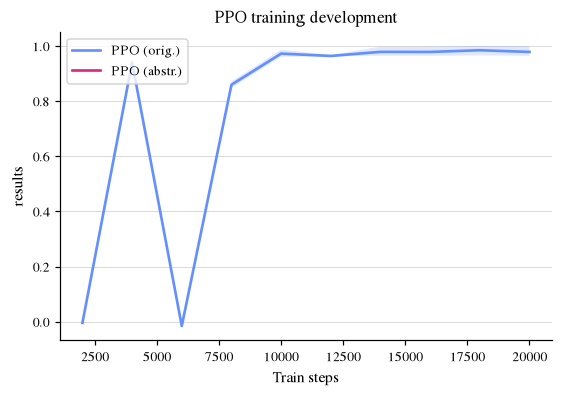

In [16]:
plot_logged_data([outpath_original + "log/evaluations.npz", outpath_abstracted + "log/evaluations.npz", 
                  ], labels=["PPO (orig.)", "PPO (abstr.)", 
                             ], key="results",
                 title="PPO training development", path_output=f"{PLOT_PATH}/ppo_training_curve.pdf")

rl_model_original = sb3.PPO.load(outpath_original + "ppo_model")
rl_model_abstracted = sb3.PPO.load(outpath_abstracted + "ppo_model")

In [17]:
rl_policy_original = SB3Policy(rl_model_original, generative_model, deterministic=True)
trajectories_rl_original = generative_model.simulate(policy=rl_policy_original, n_steps=n_simulation_steps, seed=SEED)
mean_rewards_rl_original = get_mean_reward_from_trajectories(trajectories_rl_original)

rl_policy_abstracted = SB3Policy(rl_model_abstracted, generative_model, deterministic=True)
trajectories_rl_abstracted = generative_model.simulate(policy=rl_policy_abstracted, n_steps=n_simulation_steps, seed=SEED)
mean_rewards_rl_abstracted = get_mean_reward_from_trajectories(trajectories_rl_abstracted)

Simulating:   0%|          | 0/100000 [00:00<?, ?it/s]

Simulating:   0%|          | 0/100000 [00:00<?, ?it/s]

Mean cumulative reward on the original environment:
	Abstraction policy (model checked):  91.75821212710902
	PPO policy:                          92.37751869795274
	PPO policy (abstracted):             -2475.2475247524753


/home/maris/tacas/VeriGym/examples/workflow_utils.py:370: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


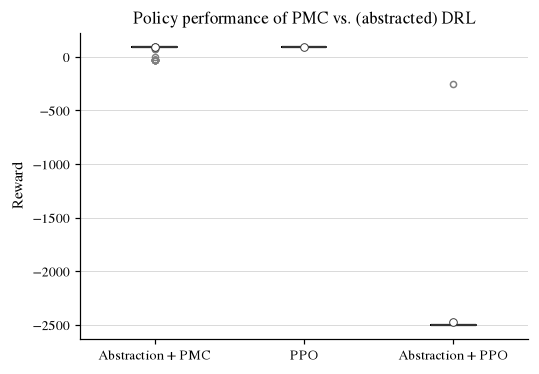

In [18]:
episode_returns = lambda trajs: [float(np.sum([t[2] for t in traj])) for traj in trajs]
print("Mean cumulative reward on the original environment:")
print("\tAbstraction policy (model checked): ", mean_rewards_original)
print("\tPPO policy:                         ", mean_rewards_rl_original)
print("\tPPO policy (abstracted):            ", mean_rewards_rl_abstracted)
plot_compare_policy_eval([episode_returns(trajectories_original), episode_returns(trajectories_rl_original), episode_returns(trajectories_rl_abstracted)],
                         labels=["Abstraction + PMC", "PPO", "Abstraction + PPO", ], title="Policy performance of PMC vs. (abstracted) DRL",
                         path_output=f"{PLOT_PATH}/comparing_abstraction_policies_with_abstracted_ppo.pdf")


/home/maris/tacas/VeriGym/examples/workflow_utils.py:370: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


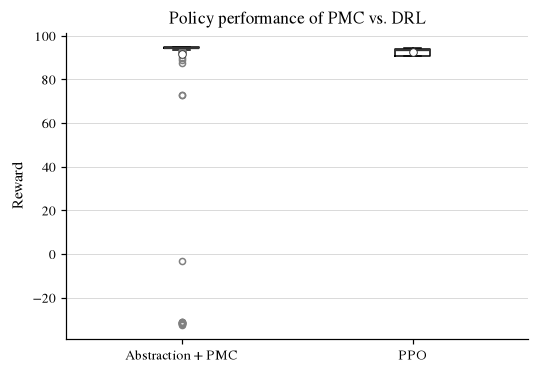

In [19]:
plot_compare_policy_eval([episode_returns(trajectories_original), episode_returns(trajectories_rl_original)],
                         labels=["Abstraction + PMC", "PPO"], title="Policy performance of PMC vs. DRL", path_output=f"{PLOT_PATH}/comparing_abstraction_policies.pdf")
